# 05 — Explainability (SHAP)
Global and local SHAP explanations for the best-performing supervised
model (XGBoost, SMOTE strategy), plus the Autoencoder's natural
per-feature reconstruction-error explanation. Also exports the artefacts
the dashboard (`dashboard/app.py`) needs.


In [1]:
# ---------------------------------------------------------------------------
# Make the src/ package importable from inside notebooks/, and fix all
# random seeds so this notebook is reproducible (Section 14 requirement).
# ---------------------------------------------------------------------------
import sys, os
sys.path.insert(0, os.path.abspath(".."))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src import preprocessing, features, models, evaluation, explainability

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
pd.set_option("display.max_columns", 50)
plt.rcParams["figure.figsize"] = (8, 4)


In [2]:
import joblib
import shap

X_test = pd.read_csv("../data/processed/X_test.csv")
y_test = pd.read_csv("../data/processed/y_test.csv").squeeze("columns")

xgb_model = joblib.load("../models/xgboost_smote.joblib")
autoencoder = joblib.load("../models/autoencoder.joblib")


C:\Users\user\AppData\Local\Temp\ipykernel_16688\1682564374.py:5: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(shap_values, sample, show=True)


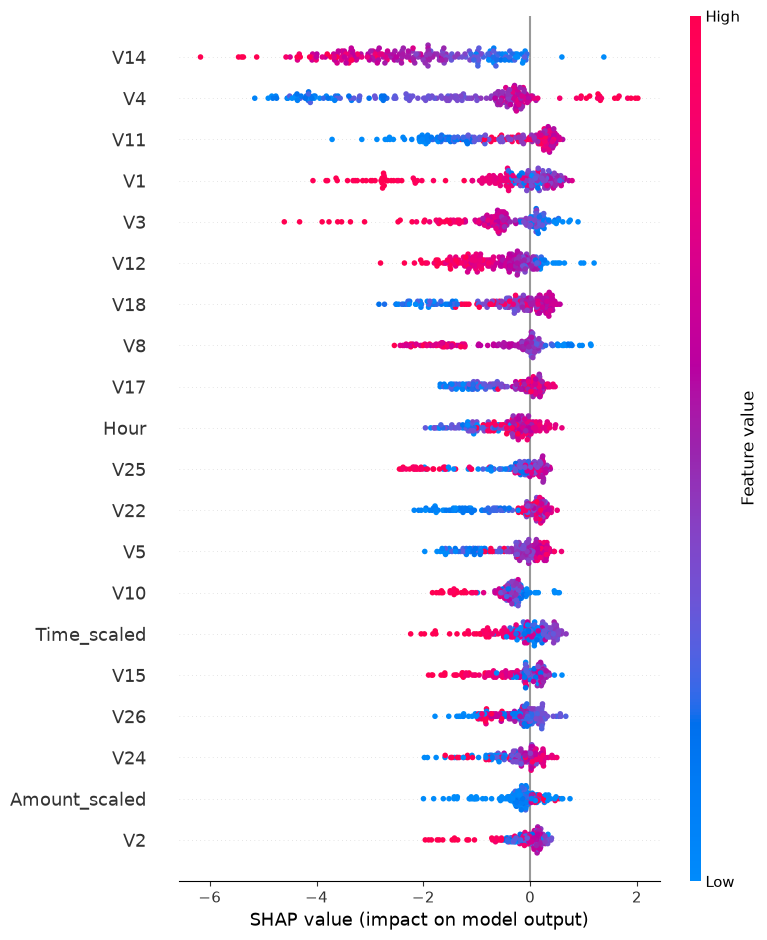

In [3]:
explainer = explainability.get_tree_explainer(xgb_model)
sample = X_test.sample(min(200, len(X_test)), random_state=RANDOM_STATE)
shap_values = explainability.global_shap_values(explainer, sample)

shap.summary_plot(shap_values, sample, show=True)


**Reporting guidance (RQ4 — which features contribute most):** the
summary plot above answers Research Question 4 directly; list the top
5-6 features it surfaces in your write-up.


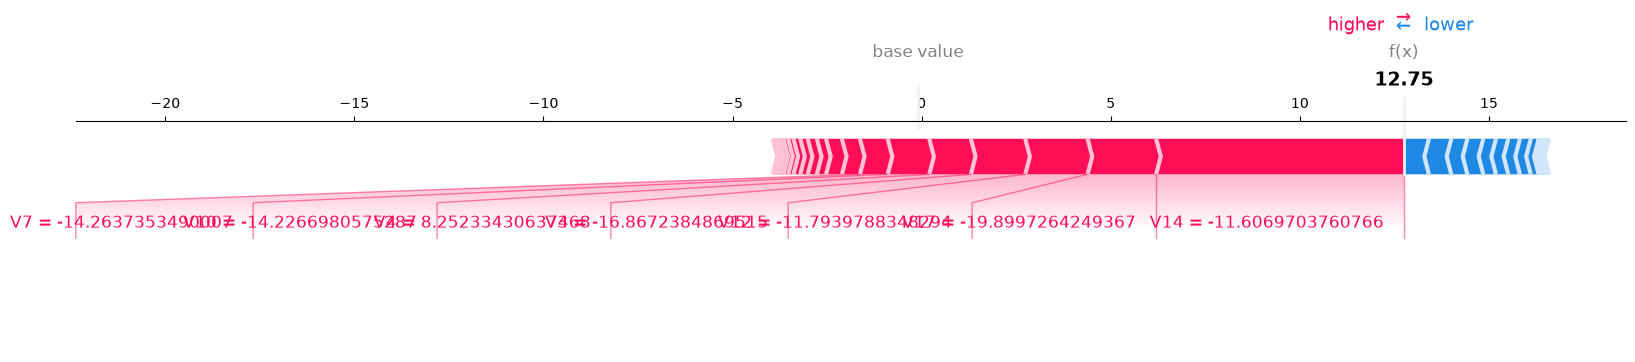

In [4]:
# Local explanation: the transaction the model is most confident is fraud.
fraud_scores = xgb_model.predict_proba(X_test)[:, 1]
most_suspicious_idx = int(np.argmax(fraud_scores))
instance = X_test.iloc[[most_suspicious_idx]]

instance_shap = explainability.local_explanation(explainer, instance)
shap.force_plot(explainer.expected_value, instance_shap[0], instance, matplotlib=True, show=True)


In [5]:
top_features = explainability.top_shap_features(explainer, instance, top_n=5)
print(f"Fraud-risk score for this transaction: {fraud_scores[most_suspicious_idx]:.1%}\n")
print("Top contributing features (positive = pushes toward fraud):")
top_features


Fraud-risk score for this transaction: 100.0%

Top contributing features (positive = pushes toward fraud):


V14    6.552142
V17    1.811915
V12    1.648466
V3     1.437368
V4     1.099884
dtype: float32

In [6]:
# The Autoencoder's own explanation mechanism, for comparison (Research
# Question 5 -- do explanations stay consistent across paradigms?).
reconstructed = autoencoder.predict(X_test)
flagged_idx = int(np.argmax(np.mean((X_test.values - reconstructed) ** 2, axis=1)))

ae_explanation = explainability.autoencoder_feature_errors(
    X_test.iloc[flagged_idx].values, reconstructed[flagged_idx], X_test.columns
)
print("Top features driving the Autoencoder's flagged transaction:")
ae_explanation.head(5)


Top features driving the Autoencoder's flagged transaction:


V20     7860.108305
V27     1112.920187
Hour     537.303034
V7       412.493504
V28      339.555636
dtype: float64

In [7]:
# ---------------------------------------------------------------------------
# Export artefacts for the Streamlit dashboard (dashboard/app.py).
# ---------------------------------------------------------------------------
os.makedirs("../models", exist_ok=True)
X_test.sample(min(50, len(X_test)), random_state=RANDOM_STATE).to_csv(
    "../data/processed/sample_test_transactions.csv", index=False
)
print("Saved a transaction sample to data/processed/ for the dashboard to load.")
print("Dashboard also needs: models/xgboost_smote.joblib, models/amount_time_scaler.joblib "
      "(both already saved by notebooks 02-03).")


Saved a transaction sample to data/processed/ for the dashboard to load.
Dashboard also needs: models/xgboost_smote.joblib, models/amount_time_scaler.joblib (both already saved by notebooks 02-03).
